# Notebook 05 — Klasifikasi Pergerakan Harga S&P 500 dengan LSTM + Sentimen Berita

**Tujuan:** Memprediksi arah pergerakan harga penutupan index S&P 500 keesokan harinya (naik/turun) menggunakan model LSTM berbasis PyTorch, dengan penggabungan fitur OHLCV dan sentimen berita harian (early fusion).

---

**Data Input:**
- `GSPC_2018_2024_no_extended_feature.csv` — Data harga OHLCV harian S&P 500 (sudah pre-scaled ke range [0,1])
- `headlines_daily_sentiment.csv` — Sentimen rata-rata headline berita keuangan harian

**Alur Pipeline:**
1. Load & Merge kedua dataset (OHLCV + sentiment_mean)
2. Buat target label biner: `y=1` jika harga naik besok, `y=0` jika turun
3. Split kronologis: Train (70%) / Val (15%) / Test (15%)
4. Sliding window sequence creation untuk LSTM
5. Definisi arsitektur LSTM (PyTorch)
6. Hyperparameter Tuning via Grid Search (metrik: Val F2-Score)
7. Pelatihan model final dengan konfigurasi terbaik
8. Evaluasi: Confusion Matrix · Accuracy · Precision · Recall · F2-Score · Overfitting/Underfitting

In [3]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from itertools import product

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    ConfusionMatrixDisplay,
)

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
plt.style.use("seaborn-v0_8-darkgrid")

# ── Reproducibility ──────────────────────────────────────────────────────────
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch version : {torch.__version__}")
print(f"Device          : {DEVICE}")
print(f"CUDA available  : {torch.cuda.is_available()}")

# ── Paths ─────────────────────────────────────────────────────────────────────
BASE_DIR     = Path("..").resolve()
DATA_DIR     = BASE_DIR / "data" / "processed"
ARTIFACT_DIR = BASE_DIR / "data" / "artifacts" / "lstm_weights"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

STOCK_PATH     = DATA_DIR / "stocks"    / "GSPC_2018_2024_no_extended_feature.csv"
SENTIMENT_PATH = DATA_DIR / "sentiment" / "headlines_daily_sentiment.csv"

print(f"\nStock path    : {STOCK_PATH}")
print(f"Sentiment path: {SENTIMENT_PATH}")

PyTorch version : 2.6.0+cu124
Device          : cuda
CUDA available  : True

Stock path    : E:\forecasting_index_snp500\stock_prediction\data\processed\stocks\GSPC_2018_2024_no_extended_feature.csv
Sentiment path: E:\forecasting_index_snp500\stock_prediction\data\processed\sentiment\headlines_daily_sentiment.csv


---
## 1. Load & Merge Data

In [4]:
# ── Load stock OHLCV ──────────────────────────────────────────────────────────
df_stock = pd.read_csv(STOCK_PATH, parse_dates=["Date"])
df_stock = df_stock.sort_values("Date").reset_index(drop=True)

print("=== Stock Data (OHLCV) ===")
print(f"Shape : {df_stock.shape}")
print(f"Range : {df_stock['Date'].min().date()} → {df_stock['Date'].max().date()}")
print(df_stock.head(5))
print(f"\nNaN  : {df_stock.isnull().sum().to_dict()}")
print(f"Stats:\n{df_stock.describe().round(4)}")

=== Stock Data (OHLCV) ===
Shape : (1552, 6)
Range : 2018-01-02 → 2024-03-04
        Date      Open      High       Low     Close    Volume
0 2018-01-02  0.138374  0.138704  0.167103  0.158090  0.340543
1 2018-01-03  0.143345  0.145191  0.172353  0.164039  0.355237
2 2018-01-04  0.150901  0.150428  0.179609  0.167808  0.370604
3 2018-01-05  0.155133  0.155398  0.182624  0.174416  0.324690
4 2018-01-08  0.159125  0.157174  0.185922  0.175988  0.325380

NaN  : {'Date': 0, 'Open': 0, 'High': 0, 'Low': 0, 'Close': 0, 'Volume': 0}
Stats:
                             Date       Open       High        Low      Close  \
count                        1552  1552.0000  1552.0000  1552.0000  1552.0000   
mean   2021-01-30 20:08:58.144330     0.4694     0.4720     0.4801     0.4784   
min           2018-01-02 00:00:00     0.0000     0.0000     0.0000     0.0000   
25%           2019-07-18 18:00:00     0.2150     0.2137     0.2361     0.2274   
50%           2021-02-01 12:00:00     0.5066     0.5119 

In [5]:
# ── Load sentiment ────────────────────────────────────────────────────────────
df_sentiment = pd.read_csv(SENTIMENT_PATH, parse_dates=["Date"])
df_sentiment = df_sentiment.sort_values("Date").reset_index(drop=True)

print("=== Sentiment Data ===")
print(f"Shape : {df_sentiment.shape}")
print(f"Range : {df_sentiment['Date'].min().date()} → {df_sentiment['Date'].max().date()}")
print(df_sentiment.head(5))
print(f"\nNaN  : {df_sentiment.isnull().sum().to_dict()}")

=== Sentiment Data ===
Shape : (3504, 7)
Range : 2008-01-02 → 2024-03-04
        Date  headline_count  sentiment_mean  sentiment_pos  sentiment_neg  \
0 2008-01-02               3       -0.522108            0.0       0.666667   
1 2008-01-03               1        0.861627            1.0       0.000000   
2 2008-01-07               1        0.586567            1.0       0.000000   
3 2008-01-09               2       -0.421696            0.0       0.500000   
4 2008-01-10               1        0.542341            1.0       0.000000   

   sentiment_neu sentiment_label  
0       0.333333        negative  
1       0.000000        positive  
2       0.000000        positive  
3       0.500000        negative  
4       0.000000        positive  

NaN  : {'Date': 0, 'headline_count': 0, 'sentiment_mean': 0, 'sentiment_pos': 0, 'sentiment_neg': 0, 'sentiment_neu': 0, 'sentiment_label': 0}


In [6]:
# ── Merge: Stock (left) ← Sentiment ──────────────────────────────────────────
# Ambil hanya sentiment_mean dari sentiment dataset
df_sent_daily = df_sentiment[["Date", "sentiment_mean"]].copy()

# Left join: setiap hari bursa ada, tapi tidak semua hari ada berita
df = df_stock.merge(df_sent_daily, on="Date", how="left")

# Forward-fill: hari tanpa berita pakai sentimen hari sebelumnya
df["sentiment_mean"] = df["sentiment_mean"].ffill()

# Backfill sisa NaN di awal (jika hari pertama bursa belum ada berita)
df["sentiment_mean"] = df["sentiment_mean"].bfill()

# Jika masih ada NaN (unlikely), isi dengan 0 (netral)
df["sentiment_mean"] = df["sentiment_mean"].fillna(0.0)

df = df.sort_values("Date").reset_index(drop=True)

print(f"Shape setelah merge : {df.shape}")
print(f"Date range          : {df['Date'].min().date()} → {df['Date'].max().date()}")
print(f"\nMissing values setelah merge:\n{df.isnull().sum()}")
print(f"\nSample 5 baris pertama:")
print(df.head())

Shape setelah merge : (1552, 7)
Date range          : 2018-01-02 → 2024-03-04

Missing values setelah merge:
Date              0
Open              0
High              0
Low               0
Close             0
Volume            0
sentiment_mean    0
dtype: int64

Sample 5 baris pertama:
        Date      Open      High       Low     Close    Volume  sentiment_mean
0 2018-01-02  0.138374  0.138704  0.167103  0.158090  0.340543        0.311223
1 2018-01-03  0.143345  0.145191  0.172353  0.164039  0.355237       -0.018505
2 2018-01-04  0.150901  0.150428  0.179609  0.167808  0.370604        0.000000
3 2018-01-05  0.155133  0.155398  0.182624  0.174416  0.324690        0.071510
4 2018-01-08  0.159125  0.157174  0.185922  0.175988  0.325380        0.152372


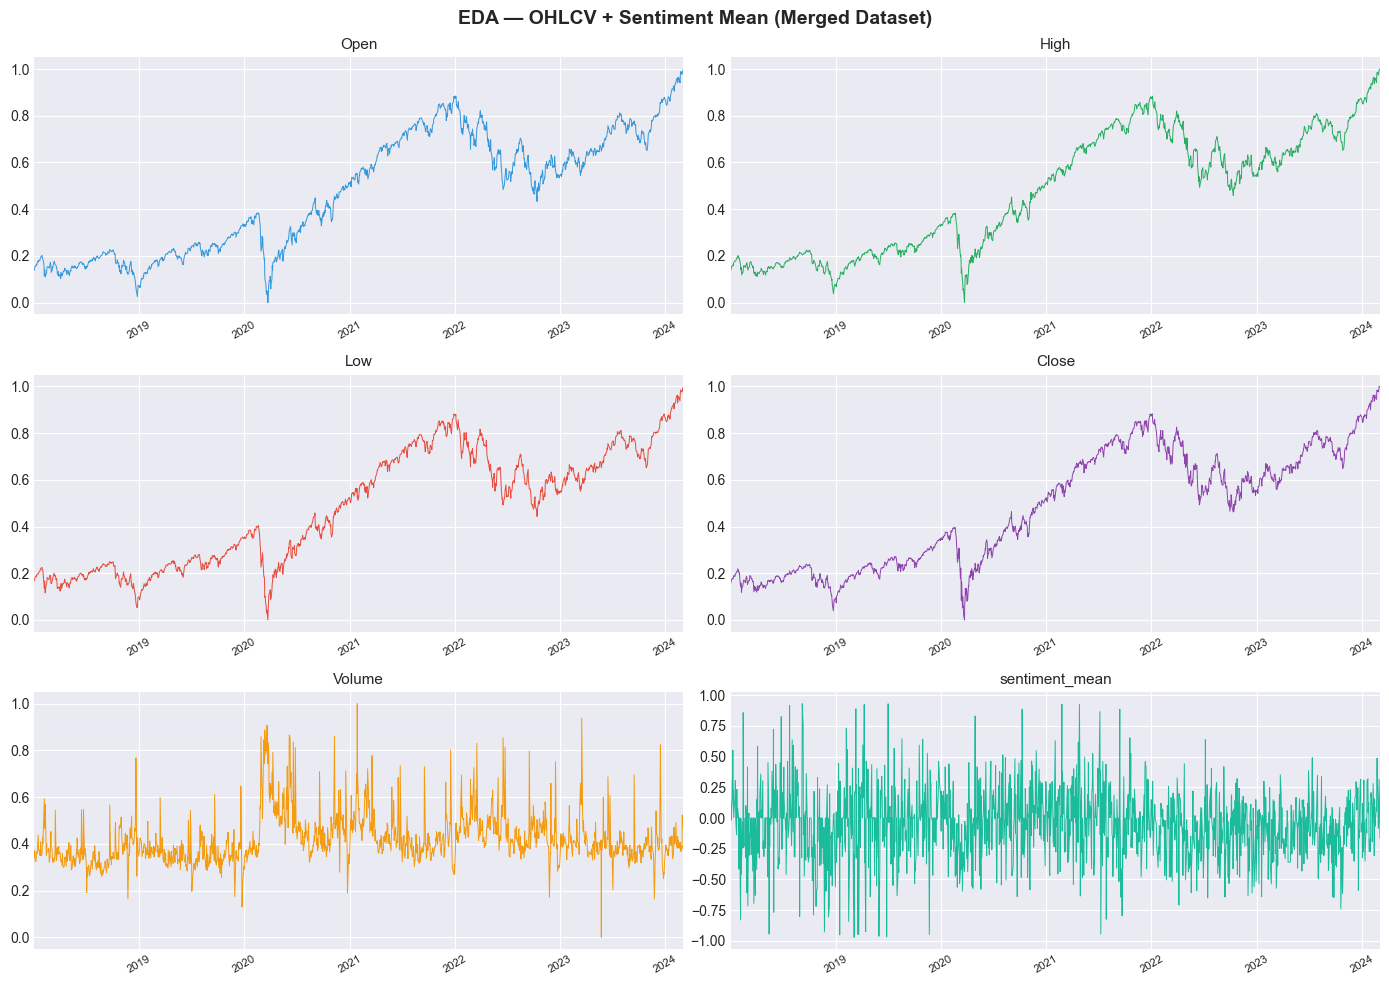


Korelasi Pearson antar fitur:
                 Open   High    Low  Close  Volume  sentiment_mean
Open            1.000  1.000  0.999  0.999   0.078           0.006
High            1.000  1.000  0.999  0.999   0.087           0.006
Low             0.999  0.999  1.000  0.999   0.063           0.015
Close           0.999  0.999  0.999  1.000   0.074           0.015
Volume          0.078  0.087  0.063  0.074   1.000          -0.095
sentiment_mean  0.006  0.006  0.015  0.015  -0.095           1.000


In [7]:
# ── EDA: Visualisasi Semua Fitur ──────────────────────────────────────────────
FEATURE_COLS = ["Open", "High", "Low", "Close", "Volume", "sentiment_mean"]

fig, axes = plt.subplots(3, 2, figsize=(14, 10))
fig.suptitle("EDA — OHLCV + Sentiment Mean (Merged Dataset)", fontsize=14, fontweight="bold")

plot_info = {
    "Open"          : "#3498db",
    "High"          : "#27ae60",
    "Low"           : "#e74c3c",
    "Close"         : "#8e44ad",
    "Volume"        : "#f39c12",
    "sentiment_mean": "#1abc9c",
}
for ax, (col, color) in zip(axes.flatten(), plot_info.items()):
    ax.plot(df["Date"], df[col], linewidth=0.7, color=color)
    ax.set_title(col, fontsize=11)
    ax.tick_params(axis="x", rotation=30, labelsize=8)
    ax.set_xlim(df["Date"].min(), df["Date"].max())

plt.tight_layout()
plt.savefig("eda_merged_features.png", dpi=100, bbox_inches="tight")
plt.show()

# Korelasi antar fitur
print("\nKorelasi Pearson antar fitur:")
print(df[FEATURE_COLS].corr().round(3))

---
## 2. Feature Engineering & Label Creation

**Target (y):** Klasifikasi biner arah harga penutupan keesokan hari.
- `y = 1` → **Up**: `Close[t+1] > Close[t]`
- `y = 0` → **Down/Flat**: `Close[t+1] ≤ Close[t]`

**Fitur (X):** 6 kolom → `Open, High, Low, Close, Volume, sentiment_mean`

> Catatan: OHLCV sudah pre-scaled ke [0,1]. `sentiment_mean` akan di-scale terpisah ke [0,1] pada tahap preprocessing agar range setara, dengan scaler yang hanya di-fit pada data train (anti-leakage).

Shape setelah labeling : (1552, 8)
Date range             : 2018-01-02 → 2024-03-04

Distribusi label:
  Down (0) :  713  (45.9%)
  Up   (1) :  839  (54.1%)


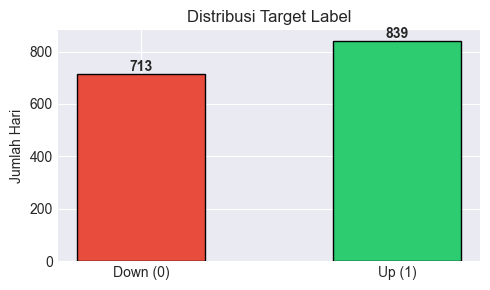

In [8]:
# ── Buat label biner: apakah Close besok lebih tinggi dari hari ini? ──────────
df["target"] = (df["Close"].shift(-1) > df["Close"]).astype(int)

# Hapus baris terakhir (tidak memiliki label karena shift(-1))
df = df.dropna(subset=["target"]).reset_index(drop=True)
df["target"] = df["target"].astype(int)

print(f"Shape setelah labeling : {df.shape}")
print(f"Date range             : {df['Date'].min().date()} → {df['Date'].max().date()}")
print()

vc = df["target"].value_counts().sort_index()
print("Distribusi label:")
print(f"  Down (0) : {vc[0]:4d}  ({vc[0]/len(df)*100:.1f}%)")
print(f"  Up   (1) : {vc[1]:4d}  ({vc[1]/len(df)*100:.1f}%)")

# Plot distribusi
fig, ax = plt.subplots(figsize=(5, 3))
bars = ax.bar(["Down (0)", "Up (1)"], [vc[0], vc[1]],
              color=["#e74c3c", "#2ecc71"], edgecolor="k", width=0.5)
ax.set_title("Distribusi Target Label")
ax.set_ylabel("Jumlah Hari")
for bar in bars:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 3,
            f"{int(bar.get_height())}", ha="center", va="bottom", fontsize=10, fontweight="bold")
plt.tight_layout()
plt.savefig("label_distribution.png", dpi=100, bbox_inches="tight")
plt.show()

---
## 3. Train / Validation / Test Split & Scaling

Split dilakukan secara **kronologis** (tidak acak) untuk mensimulasikan prediksi masa depan yang realistis:
- **Train  :** 70% data paling awal
- **Val    :** 15% data tengah
- **Test   :** 15% data paling akhir (tidak pernah dilihat model)

Scaling `sentiment_mean` ke [0,1] menggunakan `MinMaxScaler` yang **hanya di-fit pada data train**, lalu diterapkan ke val & test.

In [9]:
# ── Chronological split ───────────────────────────────────────────────────────
N         = len(df)
train_end = int(N * 0.70)
val_end   = int(N * 0.85)

df_train = df.iloc[:train_end].copy()
df_val   = df.iloc[train_end:val_end].copy()
df_test  = df.iloc[val_end:].copy()

print(f"Train : {len(df_train):4d} hari  "
      f"({df_train['Date'].iloc[0].date()} → {df_train['Date'].iloc[-1].date()})")
print(f"Val   : {len(df_val):4d} hari  "
      f"({df_val['Date'].iloc[0].date()} → {df_val['Date'].iloc[-1].date()})")
print(f"Test  : {len(df_test):4d} hari  "
      f"({df_test['Date'].iloc[0].date()} → {df_test['Date'].iloc[-1].date()})")

# ── Scale sentiment_mean ke [0,1] — fit HANYA pada train (anti-leakage) ──────
sent_scaler = MinMaxScaler(feature_range=(0, 1))
df_train["sentiment_mean"] = sent_scaler.fit_transform(df_train[["sentiment_mean"]])
df_val["sentiment_mean"]   = sent_scaler.transform(df_val[["sentiment_mean"]])
df_test["sentiment_mean"]  = sent_scaler.transform(df_test[["sentiment_mean"]])

# ── Ekstrak array fitur & label ───────────────────────────────────────────────
X_train_raw = df_train[FEATURE_COLS].values.astype(np.float32)
X_val_raw   = df_val[FEATURE_COLS].values.astype(np.float32)
X_test_raw  = df_test[FEATURE_COLS].values.astype(np.float32)

y_train = df_train["target"].values.astype(np.int64)
y_val   = df_val["target"].values.astype(np.int64)
y_test  = df_test["target"].values.astype(np.int64)

print(f"\nShape X_train : {X_train_raw.shape}  |  y_train : {y_train.shape}")
print(f"Shape X_val   : {X_val_raw.shape}   |  y_val   : {y_val.shape}")
print(f"Shape X_test  : {X_test_raw.shape}   |  y_test  : {y_test.shape}")
print(f"\nClass balance Train — Down: {(y_train==0).sum()} | Up: {(y_train==1).sum()}")
print(f"Class balance Val   — Down: {(y_val==0).sum()}   | Up: {(y_val==1).sum()}")
print(f"Class balance Test  — Down: {(y_test==0).sum()}   | Up: {(y_test==1).sum()}")

Train : 1086 hari  (2018-01-02 → 2022-04-25)
Val   :  233 hari  (2022-04-26 → 2023-03-29)
Test  :  233 hari  (2023-03-30 → 2024-03-04)

Shape X_train : (1086, 6)  |  y_train : (1086,)
Shape X_val   : (233, 6)   |  y_val   : (233,)
Shape X_test  : (233, 6)   |  y_test  : (233,)

Class balance Train — Down: 484 | Up: 602
Class balance Val   — Down: 126   | Up: 107
Class balance Test  — Down: 103   | Up: 130


In [10]:
# ── Sliding Window Sequence Creation ─────────────────────────────────────────

def create_sequences(X: np.ndarray, y: np.ndarray, seq_len: int):
    """
    Membuat pasangan (sequence, label) dari time series.
    Input  : X[t], y[t]
    Output : X_seq[i] = X[i : i+seq_len], y_seq[i] = y[i+seq_len]
    """
    Xs, ys = [], []
    for i in range(seq_len, len(X)):
        Xs.append(X[i - seq_len : i])
        ys.append(y[i])
    return np.array(Xs, dtype=np.float32), np.array(ys, dtype=np.int64)


class StockSequenceDataset(Dataset):
    """PyTorch Dataset untuk sequence LSTM."""
    def __init__(self, X_seq: np.ndarray, y_seq: np.ndarray):
        self.X = torch.from_numpy(X_seq)   # shape: (N, seq_len, n_features)
        self.y = torch.from_numpy(y_seq)   # shape: (N,)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


def build_dataloaders(X_train, y_train, X_val, y_val, X_test, y_test,
                      seq_len: int, batch_size: int):
    """Buat DataLoader untuk train, val, dan test."""
    X_tr_seq, y_tr_seq = create_sequences(X_train, y_train, seq_len)
    X_vl_seq, y_vl_seq = create_sequences(X_val,   y_val,   seq_len)
    X_te_seq, y_te_seq = create_sequences(X_test,  y_test,  seq_len)

    train_ds = StockSequenceDataset(X_tr_seq, y_tr_seq)
    val_ds   = StockSequenceDataset(X_vl_seq, y_vl_seq)
    test_ds  = StockSequenceDataset(X_te_seq, y_te_seq)

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=False, drop_last=True)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False)
    test_loader  = DataLoader(test_ds,  batch_size=batch_size, shuffle=False)

    return train_loader, val_loader, test_loader, X_te_seq, y_te_seq


# Demo: seq_len=20
_X_demo, _y_demo = create_sequences(X_train_raw, y_train, seq_len=20)
print(f"Contoh sequence (seq_len=20):")
print(f"  X shape: {_X_demo.shape}  →  (n_samples, seq_len, n_features)")
print(f"  y shape: {_y_demo.shape}")
print("Dataset & DataLoader utility siap.")

Contoh sequence (seq_len=20):
  X shape: (1066, 20, 6)  →  (n_samples, seq_len, n_features)
  y shape: (1066,)
Dataset & DataLoader utility siap.


---
## 4. Definisi Arsitektur LSTM (PyTorch)

**Arsitektur:**
```
Input (seq_len × 6) → LSTM (hidden_size, num_layers) → Dropout → FC → Softmax (2 kelas)
```
- `batch_first=True`: input shape `(batch, seq_len, input_size)`
- Hanya mengambil hidden state pada **timestep terakhir** untuk klasifikasi
- `nn.LSTM` internal dropout hanya aktif jika `num_layers > 1`

In [11]:
class LSTMClassifier(nn.Module):
    """
    LSTM Classifier untuk prediksi arah harga S&P 500.

    Args:
        input_size  : jumlah fitur per timestep (6: OHLCV + sentiment)
        hidden_size : jumlah unit LSTM
        num_layers  : jumlah layer LSTM yang ditumpuk
        dropout     : probabilitas dropout (regularisasi)
        num_classes : 2 (Up / Down)
    """
    def __init__(self, input_size: int, hidden_size: int,
                 num_layers: int, dropout: float, num_classes: int = 2):
        super().__init__()
        self.hidden_size = hidden_size
        self.num_layers  = num_layers

        self.lstm = nn.LSTM(
            input_size  = input_size,
            hidden_size = hidden_size,
            num_layers  = num_layers,
            batch_first = True,
            dropout     = dropout if num_layers > 1 else 0.0,
        )
        self.dropout = nn.Dropout(p=dropout)
        self.fc      = nn.Linear(hidden_size, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x: (batch, seq_len, input_size)
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size, device=x.device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size, device=x.device)

        out, _  = self.lstm(x, (h0, c0))   # (batch, seq_len, hidden_size)
        out     = out[:, -1, :]             # ambil timestep terakhir → (batch, hidden_size)
        out     = self.dropout(out)
        out     = self.fc(out)              # (batch, num_classes)
        return out


INPUT_SIZE = len(FEATURE_COLS)  # 6
print(f"Input size: {INPUT_SIZE} fitur ({', '.join(FEATURE_COLS)})")

# Contoh inisialisasi & ringkasan model
_demo_model = LSTMClassifier(
    input_size  = INPUT_SIZE,
    hidden_size = 64,
    num_layers  = 2,
    dropout     = 0.3,
)
print()
print(_demo_model)
total_params = sum(p.numel() for p in _demo_model.parameters() if p.requires_grad)
print(f"\nTotal trainable parameters: {total_params:,}")

Input size: 6 fitur (Open, High, Low, Close, Volume, sentiment_mean)

LSTMClassifier(
  (lstm): LSTM(6, 64, num_layers=2, batch_first=True, dropout=0.3)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=64, out_features=2, bias=True)
)

Total trainable parameters: 51,842


---
## 5. Hyperparameter Tuning — Grid Search

**Grid Parameter:**

| Parameter       | Nilai yang dicoba     | Keterangan                         |
|-----------------|----------------------|------------------------------------|
| `seq_len`       | 10, 20, 30           | Panjang window lookback (hari)     |
| `hidden_size`   | 32, 64, 128          | Jumlah unit hidden LSTM            |
| `num_layers`    | 1, 2                 | Jumlah layer LSTM ditumpuk         |
| `dropout`       | 0.2, 0.4             | Dropout regularisasi               |
| `learning_rate` | 1e-3, 5e-4           | Step size Adam optimizer           |
| `batch_size`    | 32, 64               | Batch size training                |

**Metrik seleksi:** Val **F2-Score** (β=2) — menekankan Recall lebih dari Precision, cocok untuk kasus di mana melewatkan sinyal "Up" lebih merugikan daripada false alarm.

**Training per konfigurasi:** max 80 epoch, early stopping patience 20 epoch.

In [12]:
# ── Helper Functions untuk Training ──────────────────────────────────────────

def compute_class_weights(y: np.ndarray, device: torch.device) -> torch.Tensor:
    """Inverse-frequency class weights untuk handle class imbalance."""
    counts  = np.bincount(y)
    weights = 1.0 / (counts + 1e-9)
    weights = weights / weights.sum() * len(counts)
    return torch.tensor(weights, dtype=torch.float32, device=device)


def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss, correct, n = 0.0, 0, 0
    for X_batch, y_batch in loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)
        optimizer.zero_grad()
        logits = model(X_batch)
        loss   = criterion(logits, y_batch)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        total_loss += loss.item() * len(y_batch)
        correct    += (logits.argmax(1) == y_batch).sum().item()
        n          += len(y_batch)
    return total_loss / n, correct / n


@torch.no_grad()
def evaluate_loader(model, loader, criterion, device):
    """Evaluasi model pada sebuah DataLoader: return loss, f2, acc, y_true, y_pred."""
    model.eval()
    total_loss, all_preds, all_labels, n = 0.0, [], [], 0
    for X_batch, y_batch in loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)
        logits  = model(X_batch)
        loss    = criterion(logits, y_batch)
        total_loss  += loss.item() * len(y_batch)
        all_preds.extend(logits.argmax(1).cpu().numpy())
        all_labels.extend(y_batch.cpu().numpy())
        n += len(y_batch)
    y_pred   = np.array(all_preds)
    y_true   = np.array(all_labels)
    avg_loss = total_loss / n
    f2  = fbeta_score(y_true, y_pred, beta=2, zero_division=0)
    acc = accuracy_score(y_true, y_pred)
    return avg_loss, f2, acc, y_true, y_pred


def run_training(config: dict,
                 X_train, y_train, X_val, y_val, X_test, y_test,
                 device, verbose: bool = False):
    """
    Latih LSTM dengan config tertentu.
    Return: (history, best_val_f2, best_state, model,
             train_loader, val_loader, test_loader, X_te_seq, y_te_seq)
    """
    seq_len    = config["seq_len"]
    hidden     = config["hidden_size"]
    n_layers   = config["num_layers"]
    dropout    = config["dropout"]
    lr         = config["lr"]
    batch_size = config["batch_size"]
    epochs     = config.get("epochs", 80)
    early_stop = config.get("early_stop", 20)

    train_loader, val_loader, test_loader, X_te_seq, y_te_seq = build_dataloaders(
        X_train, y_train, X_val, y_val, X_test, y_test, seq_len, batch_size
    )

    class_w   = compute_class_weights(y_train, device)
    model     = LSTMClassifier(INPUT_SIZE, hidden, n_layers, dropout).to(device)
    criterion = nn.CrossEntropyLoss(weight=class_w)
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=7, min_lr=1e-6
    )

    history = {"train_loss": [], "val_loss": [],
               "train_acc": [],  "val_acc": [],
               "train_f2": [],   "val_f2": []}
    best_val_f2, best_state, patience_cnt = -np.inf, None, 0

    for epoch in range(1, epochs + 1):
        tr_loss, tr_acc               = train_one_epoch(model, train_loader, optimizer, criterion, device)
        vl_loss, vl_f2, vl_acc, _, _ = evaluate_loader(model, val_loader,   criterion, device)
        _,       tr_f2, _,     _, _  = evaluate_loader(model, train_loader, criterion, device)

        history["train_loss"].append(tr_loss)
        history["val_loss"].append(vl_loss)
        history["train_acc"].append(tr_acc)
        history["val_acc"].append(vl_acc)
        history["train_f2"].append(tr_f2)
        history["val_f2"].append(vl_f2)
        scheduler.step(vl_f2)

        if vl_f2 > best_val_f2:
            best_val_f2  = vl_f2
            best_state   = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            patience_cnt = 0
        else:
            patience_cnt += 1

        if verbose and epoch % 10 == 0:
            print(f"  Epoch {epoch:3d} | tr_loss={tr_loss:.4f} vl_loss={vl_loss:.4f}"
                  f" | tr_f2={tr_f2:.3f} vl_f2={vl_f2:.3f}")
        if patience_cnt >= early_stop:
            if verbose:
                print(f"  Early stop pada epoch {epoch}.")
            break

    return (history, best_val_f2, best_state,
            model, train_loader, val_loader, test_loader,
            X_te_seq, y_te_seq)


print("Training helper functions siap.")

Training helper functions siap.


In [13]:
# ── Grid Search ───────────────────────────────────────────────────────────────
PARAM_GRID = {
    "seq_len"    : [10, 20, 30],
    "hidden_size": [32, 64, 128],
    "num_layers" : [1, 2],
    "dropout"    : [0.2, 0.4],
    "lr"         : [1e-3, 5e-4],
    "batch_size" : [32, 64],
}

total_configs = 1
for v in PARAM_GRID.values():
    total_configs *= len(v)
print(f"Total kombinasi hyperparameter : {total_configs}")
print("Memulai Grid Search...\n")

grid_results = []

for i, combo in enumerate(product(*PARAM_GRID.values()), 1):
    config = dict(zip(PARAM_GRID.keys(), combo))
    config["epochs"]     = 80
    config["early_stop"] = 20

    try:
        history, best_val_f2, best_state, *_ = run_training(
            config,
            X_train_raw, y_train,
            X_val_raw,   y_val,
            X_test_raw,  y_test,
            device  = DEVICE,
            verbose = False,
        )
        grid_results.append({**config, "val_f2": best_val_f2})
        print(f"[{i:3d}/{total_configs}] seq={config['seq_len']:2d} h={config['hidden_size']:3d}"
              f" L={config['num_layers']} dr={config['dropout']} lr={config['lr']:.0e}"
              f" bs={config['batch_size']}  →  val_F2={best_val_f2:.4f}")
    except Exception as e:
        print(f"[{i:3d}/{total_configs}] {config}  →  ERROR: {e}")

# Buat DataFrame hasil grid search
grid_df = pd.DataFrame(grid_results).sort_values("val_f2", ascending=False).reset_index(drop=True)

print("\n" + "="*70)
print("  TOP 10 KONFIGURASI (berdasarkan Val F2-Score)")
print("="*70)
print(grid_df.head(10).to_string(index=False))

Total kombinasi hyperparameter : 144
Memulai Grid Search...



[  1/144] seq=10 h= 32 L=1 dr=0.2 lr=1e-03 bs=32  →  val_F2=0.8054
[  2/144] seq=10 h= 32 L=1 dr=0.2 lr=1e-03 bs=64  →  val_F2=0.8054
[  3/144] seq=10 h= 32 L=1 dr=0.2 lr=5e-04 bs=32  →  val_F2=0.8054
[  4/144] seq=10 h= 32 L=1 dr=0.2 lr=5e-04 bs=64  →  val_F2=0.8054
[  5/144] seq=10 h= 32 L=1 dr=0.4 lr=1e-03 bs=32  →  val_F2=0.8054
[  6/144] seq=10 h= 32 L=1 dr=0.4 lr=1e-03 bs=64  →  val_F2=0.8054
[  7/144] seq=10 h= 32 L=1 dr=0.4 lr=5e-04 bs=32  →  val_F2=0.8054
[  8/144] seq=10 h= 32 L=1 dr=0.4 lr=5e-04 bs=64  →  val_F2=0.8054
[  9/144] seq=10 h= 32 L=2 dr=0.2 lr=1e-03 bs=32  →  val_F2=0.8054
[ 10/144] seq=10 h= 32 L=2 dr=0.2 lr=1e-03 bs=64  →  val_F2=0.8054
[ 11/144] seq=10 h= 32 L=2 dr=0.2 lr=5e-04 bs=32  →  val_F2=0.8054
[ 12/144] seq=10 h= 32 L=2 dr=0.2 lr=5e-04 bs=64  →  val_F2=0.8054
[ 13/144] seq=10 h= 32 L=2 dr=0.4 lr=1e-03 bs=32  →  val_F2=0.8054
[ 14/144] seq=10 h= 32 L=2 dr=0.4 lr=1e-03 bs=64  →  val_F2=0.8054
[ 15/144] seq=10 h= 32 L=2 dr=0.4 lr=5e-04 bs=32  →  val_F2=0.

  BEST HYPERPARAMETER CONFIGURATION
  seq_len         : 20
  hidden_size     : 64
  num_layers      : 2
  dropout         : 0.4
  lr              : 0.0005
  batch_size      : 64
  epochs          : 150
  early_stop      : 30

  Best Val F2-Score : 0.8110


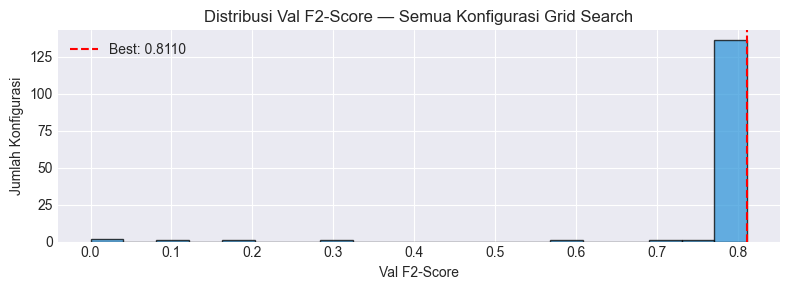

In [14]:
# ── Pilih Konfigurasi Terbaik ─────────────────────────────────────────────────
best_row    = grid_df.iloc[0]
BEST_CONFIG = {
    "seq_len"    : int(best_row["seq_len"]),
    "hidden_size": int(best_row["hidden_size"]),
    "num_layers" : int(best_row["num_layers"]),
    "dropout"    : float(best_row["dropout"]),
    "lr"         : float(best_row["lr"]),
    "batch_size" : int(best_row["batch_size"]),
    "epochs"     : 150,
    "early_stop" : 30,
}

print("=" * 50)
print("  BEST HYPERPARAMETER CONFIGURATION")
print("=" * 50)
for k, v in BEST_CONFIG.items():
    print(f"  {k:<15} : {v}")
print(f"\n  Best Val F2-Score : {best_row['val_f2']:.4f}")

# Visualisasi distribusi val_f2 dari semua konfigurasi
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(grid_df["val_f2"], bins=20, color="#3498db", edgecolor="k", alpha=0.75)
ax.axvline(best_row["val_f2"], color="red", linestyle="--", linewidth=1.5,
           label=f"Best: {best_row['val_f2']:.4f}")
ax.set_xlabel("Val F2-Score")
ax.set_ylabel("Jumlah Konfigurasi")
ax.set_title("Distribusi Val F2-Score — Semua Konfigurasi Grid Search")
ax.legend()
plt.tight_layout()
plt.savefig("grid_search_distribution.png", dpi=100, bbox_inches="tight")
plt.show()

---
## 6. Pelatihan Model Final

Melatih ulang model dengan konfigurasi terbaik dari grid search menggunakan **epoch lebih banyak** (150) dan **early stopping lebih sabar** (patience=30), kemudian menyimpan bobot terbaik ke disk.

In [15]:
print("Melatih model final dengan konfigurasi terbaik...\n")
print(f"Konfigurasi: {BEST_CONFIG}\n")

(final_history, best_val_f2_final, final_best_state,
 final_model, train_loader, val_loader, test_loader,
 X_te_seq, y_te_seq) = run_training(
    BEST_CONFIG,
    X_train_raw, y_train,
    X_val_raw,   y_val,
    X_test_raw,  y_test,
    device  = DEVICE,
    verbose = True,
)

# Load bobot terbaik ke model
final_model.load_state_dict(final_best_state)
final_model.to(DEVICE)

print(f"\nPelatihan selesai.")
print(f"Best Val F2-Score : {best_val_f2_final:.4f}")

# Simpan model
MODEL_SAVE_PATH = ARTIFACT_DIR / "lstm_nb05_best.pt"
torch.save({
    "model_state_dict" : final_best_state,
    "config"           : BEST_CONFIG,
    "feature_cols"     : FEATURE_COLS,
    "best_val_f2"      : best_val_f2_final,
}, MODEL_SAVE_PATH)
print(f"Model disimpan ke: {MODEL_SAVE_PATH}")

Melatih model final dengan konfigurasi terbaik...

Konfigurasi: {'seq_len': 20, 'hidden_size': 64, 'num_layers': 2, 'dropout': 0.4, 'lr': 0.0005, 'batch_size': 64, 'epochs': 150, 'early_stop': 30}

  Epoch  10 | tr_loss=0.6930 vl_loss=0.6930 | tr_f2=0.716 vl_f2=0.394
  Epoch  20 | tr_loss=0.6930 vl_loss=0.6931 | tr_f2=0.729 vl_f2=0.461
  Epoch  30 | tr_loss=0.6932 vl_loss=0.6929 | tr_f2=0.720 vl_f2=0.386
  Early stop pada epoch 32.

Pelatihan selesai.
Best Val F2-Score : 0.8070
Model disimpan ke: E:\forecasting_index_snp500\stock_prediction\data\artifacts\lstm_weights\lstm_nb05_best.pt


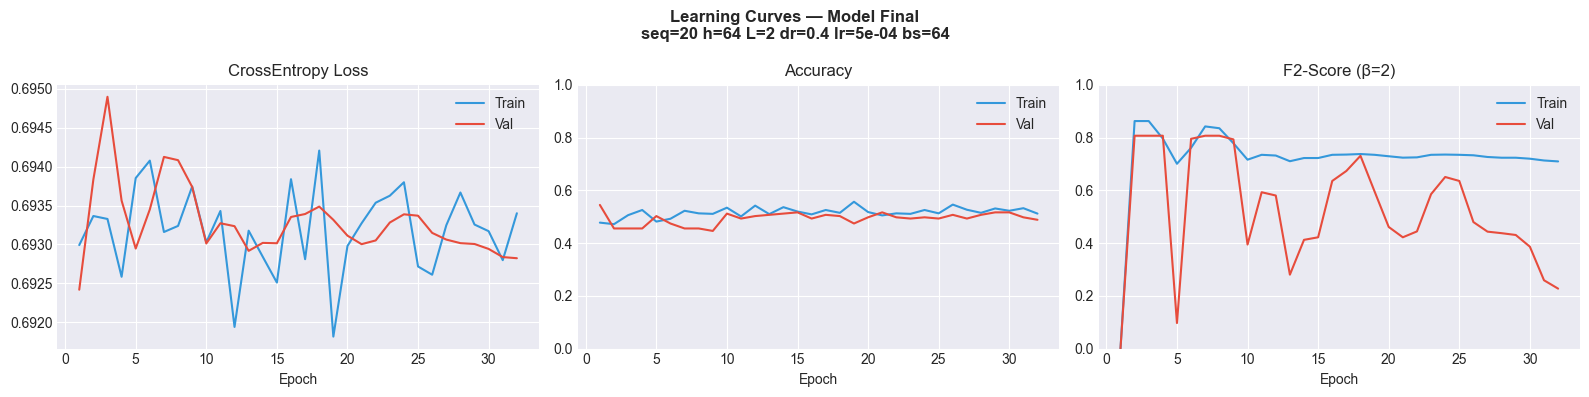

Learning curves disimpan ke: learning_curves_final.png


In [16]:
# ── Learning Curves ───────────────────────────────────────────────────────────
def plot_learning_curves(history: dict, title: str = "Learning Curves"):
    epochs_ran = len(history["train_loss"])
    x = range(1, epochs_ran + 1)

    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    fig.suptitle(title, fontsize=12, fontweight="bold")

    # Loss
    axes[0].plot(x, history["train_loss"], label="Train", color="#3498db")
    axes[0].plot(x, history["val_loss"],   label="Val",   color="#e74c3c")
    axes[0].set_title("CrossEntropy Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()

    # Accuracy
    axes[1].plot(x, history["train_acc"], label="Train", color="#3498db")
    axes[1].plot(x, history["val_acc"],   label="Val",   color="#e74c3c")
    axes[1].set_title("Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylim(0, 1)
    axes[1].legend()

    # F2-Score
    axes[2].plot(x, history["train_f2"], label="Train", color="#3498db")
    axes[2].plot(x, history["val_f2"],   label="Val",   color="#e74c3c")
    axes[2].set_title("F2-Score (β=2)")
    axes[2].set_xlabel("Epoch")
    axes[2].set_ylim(0, 1)
    axes[2].legend()

    plt.tight_layout()
    plt.savefig("learning_curves_final.png", dpi=100, bbox_inches="tight")
    plt.show()
    print("Learning curves disimpan ke: learning_curves_final.png")


plot_learning_curves(
    final_history,
    title=f"Learning Curves — Model Final\n"
          f"seq={BEST_CONFIG['seq_len']} h={BEST_CONFIG['hidden_size']}"
          f" L={BEST_CONFIG['num_layers']} dr={BEST_CONFIG['dropout']}"
          f" lr={BEST_CONFIG['lr']:.0e} bs={BEST_CONFIG['batch_size']}"
)

---
## 7. Evaluasi Model pada Test Set

Evaluasi komprehensif pada **data test** (tidak pernah terlihat saat training maupun tuning):
- Confusion Matrix (raw + ternormalisasi)
- Accuracy, Precision, Recall, F1-Score, **F2-Score**
- Classification Report per kelas

In [17]:
# ── Prediksi pada Test Set ────────────────────────────────────────────────────
class_w_eval  = compute_class_weights(y_train, DEVICE)
criterion_eval = nn.CrossEntropyLoss(weight=class_w_eval)

test_loss, test_f2, test_acc, y_true, y_pred = evaluate_loader(
    final_model, test_loader, criterion_eval, DEVICE
)

# Hitung semua metrik
test_precision = precision_score(y_true, y_pred, zero_division=0)
test_recall    = recall_score(y_true, y_pred, zero_division=0)
test_f1        = f1_score(y_true, y_pred, zero_division=0)

# Cetak ringkasan metrik
print("=" * 55)
print("       HASIL EVALUASI — TEST SET")
print("=" * 55)
print(f"  Accuracy   : {test_acc:.4f}  ({test_acc*100:.2f}%)")
print(f"  Precision  : {test_precision:.4f}")
print(f"  Recall     : {test_recall:.4f}")
print(f"  F1-Score   : {test_f1:.4f}")
print(f"  F2-Score   : {test_f2:.4f}   ← metrik utama (β=2)")
print(f"  Test Loss  : {test_loss:.4f}")
print("=" * 55)
print()
print("Classification Report (per kelas):")
print(classification_report(y_true, y_pred,
                             target_names=["Down (0)", "Up (1)"],
                             zero_division=0))

       HASIL EVALUASI — TEST SET
  Accuracy   : 0.5587  (55.87%)
  Precision  : 0.5587
  Recall     : 1.0000
  F1-Score   : 0.7169
  F2-Score   : 0.8636   ← metrik utama (β=2)
  Test Loss  : 0.6931

Classification Report (per kelas):
              precision    recall  f1-score   support

    Down (0)       0.00      0.00      0.00        94
      Up (1)       0.56      1.00      0.72       119

    accuracy                           0.56       213
   macro avg       0.28      0.50      0.36       213
weighted avg       0.31      0.56      0.40       213



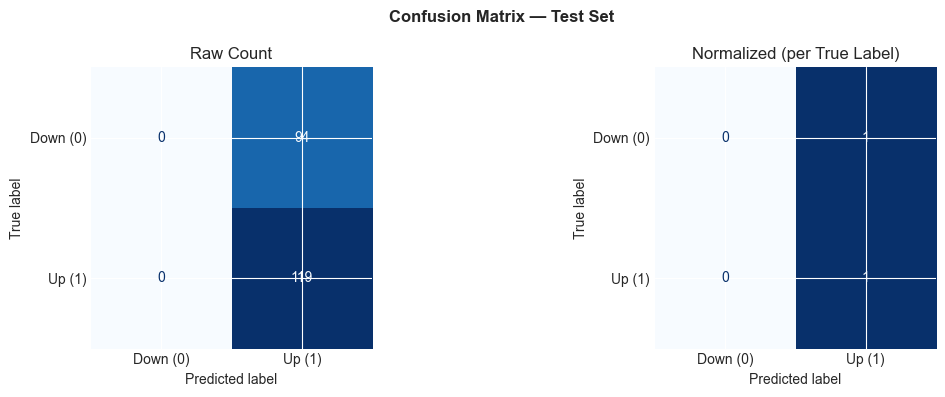


Detail Confusion Matrix:
  TP  (prediksi Up, aktual Up)   : 119
  TN  (prediksi Down, aktual Down): 0
  FP  (prediksi Up, aktual Down)  : 94
  FN  (prediksi Down, aktual Up)  : 0
  Specificity (TNR)               : 0.0000


In [18]:
# ── Confusion Matrix ──────────────────────────────────────────────────────────
cm = confusion_matrix(y_true, y_pred)
tn, fp, fn, tp = cm.ravel()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle("Confusion Matrix — Test Set", fontsize=12, fontweight="bold")

# Raw count
disp_raw = ConfusionMatrixDisplay(
    confusion_matrix = cm,
    display_labels   = ["Down (0)", "Up (1)"]
)
disp_raw.plot(ax=axes[0], colorbar=False, cmap="Blues")
axes[0].set_title("Raw Count")

# Normalized (per true label)
cm_norm = cm.astype("float") / cm.sum(axis=1, keepdims=True)
disp_norm = ConfusionMatrixDisplay(
    confusion_matrix = np.round(cm_norm, 3),
    display_labels   = ["Down (0)", "Up (1)"]
)
disp_norm.plot(ax=axes[1], colorbar=False, cmap="Blues")
axes[1].set_title("Normalized (per True Label)")

plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=100, bbox_inches="tight")
plt.show()

# Detail TP/TN/FP/FN
print(f"\nDetail Confusion Matrix:")
print(f"  TP  (prediksi Up, aktual Up)   : {tp}")
print(f"  TN  (prediksi Down, aktual Down): {tn}")
print(f"  FP  (prediksi Up, aktual Down)  : {fp}")
print(f"  FN  (prediksi Down, aktual Up)  : {fn}")
spec = tn / (tn + fp) if (tn + fp) > 0 else float("nan")
print(f"  Specificity (TNR)               : {spec:.4f}")

---
## 8. Analisis Overfitting / Underfitting

**Definisi keputusan:**

| Kondisi | Kriteria | Rekomendasi |
|---------|----------|-------------|
| **Overfitting** | Gap Train−Test > 0.10 | Tambah dropout, kurangi hidden_size/layer, lebih banyak data |
| **Underfitting** | Semua split F2 < 0.55 | Tambah kapasitas model, tambah fitur teknikal, coba CNN-LSTM |
| **Good Fit** | Gap kecil & semua metrik wajar | Iterasi fitur / arsitektur lebih lanjut jika diperlukan |

> Ambang 0.10 untuk gap dan 0.55 untuk underfit dapat disesuaikan dengan ekspektasi domain.

In [19]:
# ── Ambil metrik pada epoch terbaik ──────────────────────────────────────────
best_epoch_idx = int(np.argmax(final_history["val_f2"]))

best_train_f2  = final_history["train_f2"][best_epoch_idx]
best_val_f2_ep = final_history["val_f2"][best_epoch_idx]
best_train_acc = final_history["train_acc"][best_epoch_idx]
best_val_acc   = final_history["val_acc"][best_epoch_idx]

OVERFITTING_GAP    = 0.10   # jika gap Train-Test > ini → Overfitting
UNDERFITTING_FLOOR = 0.55   # jika semua split < ini  → Underfitting

def diagnose_fit(train_m: float, val_m: float, test_m: float,
                 metric_name: str = "F2-Score") -> str:
    gap = train_m - test_m
    if gap > OVERFITTING_GAP:
        status = "OVERFITTING"
        detail = (f"Gap Train−Test = {gap:+.4f} > threshold {OVERFITTING_GAP}. "
                  "Model hafal pola training; coba: ↑ dropout, ↓ hidden_size, "
                  "↓ num_layers, data augmentation.")
    elif train_m < UNDERFITTING_FLOOR and val_m < UNDERFITTING_FLOOR:
        status = "UNDERFITTING"
        detail = (f"Train {metric_name}={train_m:.4f} dan Val {metric_name}={val_m:.4f} "
                  f"keduanya < threshold {UNDERFITTING_FLOOR}. "
                  "Model terlalu sederhana; coba: ↑ hidden_size, ↑ num_layers, "
                  "tambah fitur teknikal (RSI, MACD, BB).")
    else:
        status = "GOOD FIT / ACCEPTABLE"
        detail = (f"Gap Train−Test = {gap:+.4f} ≤ threshold {OVERFITTING_GAP}. "
                  "Performa train dan test relatif sebanding.")
    print(f"\n[{metric_name}]")
    print(f"  Train : {train_m:.4f}  |  Val : {val_m:.4f}  |  Test : {test_m:.4f}")
    print(f"  Gap Train−Test : {gap:+.4f}")
    print(f"  Status → {status}")
    print(f"  Analisis: {detail}")
    return status

print("=" * 65)
print("   ANALISIS OVERFITTING / UNDERFITTING")
print("=" * 65)
print(f"   Epoch terbaik (berdasarkan Val F2): {best_epoch_idx + 1}")

status_f2  = diagnose_fit(best_train_f2,  best_val_f2_ep, test_f2,  "F2-Score")
status_acc = diagnose_fit(best_train_acc, best_val_acc,   test_acc, "Accuracy")

   ANALISIS OVERFITTING / UNDERFITTING
   Epoch terbaik (berdasarkan Val F2): 2

[F2-Score]
  Train : 0.8626  |  Val : 0.8070  |  Test : 0.8636
  Gap Train−Test : -0.0010
  Status → GOOD FIT / ACCEPTABLE
  Analisis: Gap Train−Test = -0.0010 ≤ threshold 0.1. Performa train dan test relatif sebanding.

[Accuracy]
  Train : 0.4717  |  Val : 0.4554  |  Test : 0.5587
  Gap Train−Test : -0.0870
  Status → UNDERFITTING
  Analisis: Train Accuracy=0.4717 dan Val Accuracy=0.4554 keduanya < threshold 0.55. Model terlalu sederhana; coba: ↑ hidden_size, ↑ num_layers, tambah fitur teknikal (RSI, MACD, BB).


In [20]:
# ── Deteksi Class Collapse (pelengkap F2/Accuracy) ───────────────────────────
# F2 & Accuracy bisa "tertipu" kalau model cuma menebak satu kelas terus.
# Cek langsung recall per-kelas: kalau salah satu kelas recall-nya ~0,
# model tidak benar-benar belajar membedakan Up vs Down — walau F2/Accuracy
# terlihat "wajar" di permukaan.

COLLAPSE_FLOOR = 0.05  # recall di bawah ini dianggap "tidak pernah menebak kelas ini"

def diagnose_class_collapse(y_true: np.ndarray, y_pred: np.ndarray, split_name: str) -> str:
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    recall_down = tn / (tn + fp) if (tn + fp) > 0 else float("nan")
    recall_up   = tp / (tp + fn) if (tp + fn) > 0 else float("nan")

    collapsed_class = None
    if recall_down <= COLLAPSE_FLOOR:
        collapsed_class = "Down (0)"
    elif recall_up <= COLLAPSE_FLOOR:
        collapsed_class = "Up (1)"

    print(f"\n[Class Collapse — {split_name}]")
    print(f"  Recall Down (0) : {recall_down:.4f}   |   Recall Up (1) : {recall_up:.4f}")
    if collapsed_class:
        status = "COLLAPSE"
        print(f"  Status → COLLAPSE TERDETEKSI pada kelas '{collapsed_class}'")
        print(f"  Analisis: model tidak pernah (recall ≤ {COLLAPSE_FLOOR}) menebak kelas '{collapsed_class}' dengan benar.")
        print(f"  F1/F2/Accuracy yang tampak wajar bisa MENYESATKAN — cek classification_report per-kelas, bukan skor gabungan saja.")
        print(f"  Kemungkinan penyebab: loss stuck/tidak turun (cek learning curve), class_weight kurang agresif,")
        print(f"  learning rate/inisialisasi bermasalah, atau early stopping berhenti di epoch yang belum konvergen.")
    else:
        status = "OK"
        print(f"  Status → OK (kedua kelas punya recall > {COLLAPSE_FLOOR})")
    return status


# Ambil prediksi final_model pada train & val (test: y_true/y_pred sudah tersedia dari evaluasi sebelumnya)
_, _, _, y_true_train, y_pred_train = evaluate_loader(final_model, train_loader, criterion_eval, DEVICE)
_, _, _, y_true_val,   y_pred_val   = evaluate_loader(final_model, val_loader,   criterion_eval, DEVICE)

print("=" * 65)
print("   DETEKSI CLASS COLLAPSE — PELENGKAP DIAGNOSIS F2 / ACCURACY")
print("=" * 65)

collapse_train = diagnose_class_collapse(y_true_train, y_pred_train, "Train")
collapse_val   = diagnose_class_collapse(y_true_val,   y_pred_val,   "Val")
collapse_test  = diagnose_class_collapse(y_true,        y_pred,       "Test")

if "COLLAPSE" in (collapse_train, collapse_val, collapse_test):
    print("\n>> KESIMPULAN: minimal satu split mengalami class collapse.")
    print(">> Status 'GOOD FIT' dari F2-Score di atas TIDAK BISA dipercaya begitu saja —")
    print(">> model kemungkinan besar belum benar-benar belajar membedakan Up vs Down.")

   DETEKSI CLASS COLLAPSE — PELENGKAP DIAGNOSIS F2 / ACCURACY

[Class Collapse — Train]
  Recall Down (0) : 0.0000   |   Recall Up (1) : 1.0000
  Status → COLLAPSE TERDETEKSI pada kelas 'Down (0)'
  Analisis: model tidak pernah (recall ≤ 0.05) menebak kelas 'Down (0)' dengan benar.
  F1/F2/Accuracy yang tampak wajar bisa MENYESATKAN — cek classification_report per-kelas, bukan skor gabungan saja.
  Kemungkinan penyebab: loss stuck/tidak turun (cek learning curve), class_weight kurang agresif,
  learning rate/inisialisasi bermasalah, atau early stopping berhenti di epoch yang belum konvergen.

[Class Collapse — Val]
  Recall Down (0) : 0.0000   |   Recall Up (1) : 1.0000
  Status → COLLAPSE TERDETEKSI pada kelas 'Down (0)'
  Analisis: model tidak pernah (recall ≤ 0.05) menebak kelas 'Down (0)' dengan benar.
  F1/F2/Accuracy yang tampak wajar bisa MENYESATKAN — cek classification_report per-kelas, bukan skor gabungan saja.
  Kemungkinan penyebab: loss stuck/tidak turun (cek learning curv

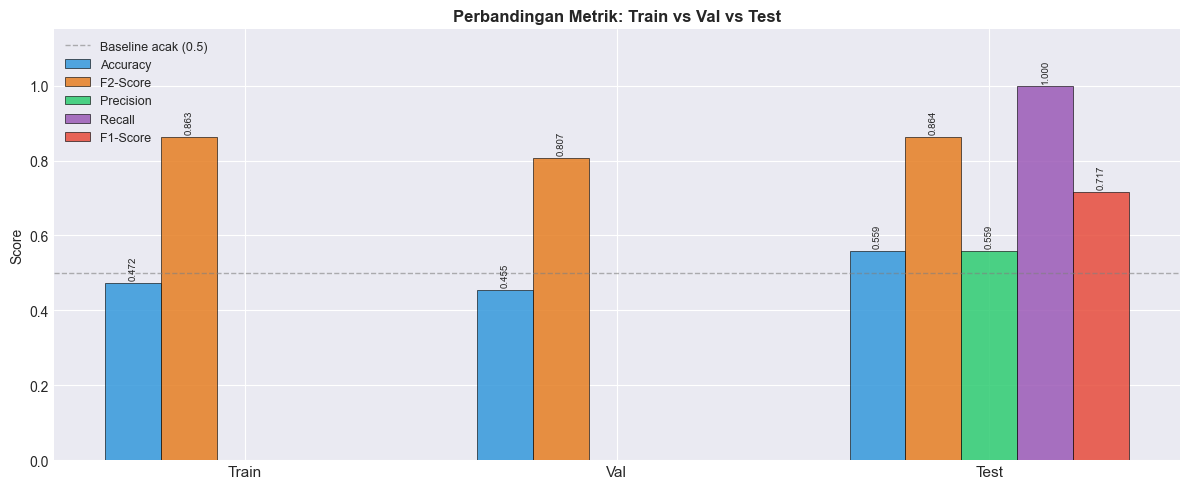

Plot perbandingan metrik disimpan ke: metrics_comparison.png


In [21]:
# ── Visualisasi Perbandingan Metrik Train / Val / Test ───────────────────────
split_labels = ["Train", "Val", "Test"]
metrics_data = {
    "Accuracy" : [best_train_acc, best_val_acc, test_acc],
    "F2-Score" : [best_train_f2,  best_val_f2_ep, test_f2],
    "Precision": [float("nan"), float("nan"), test_precision],
    "Recall"   : [float("nan"), float("nan"), test_recall],
    "F1-Score" : [float("nan"), float("nan"), test_f1],
}

x     = np.arange(len(split_labels))
bar_w = 0.15
colors = ["#3498db", "#e67e22", "#2ecc71", "#9b59b6", "#e74c3c"]

fig, ax = plt.subplots(figsize=(12, 5))
for idx, (metric_name, values) in enumerate(metrics_data.items()):
    clean_vals = [v if not np.isnan(v) else 0 for v in values]
    bars = ax.bar(x + idx * bar_w, clean_vals, bar_w,
                  label=metric_name, color=colors[idx], alpha=0.85, edgecolor="k", linewidth=0.5)
    for bar, v in zip(bars, values):
        if not np.isnan(v) and v > 0:
            ax.text(bar.get_x() + bar.get_width() / 2,
                    bar.get_height() + 0.008,
                    f"{v:.3f}", ha="center", va="bottom", fontsize=7, rotation=90)

ax.set_xticks(x + bar_w * 2)
ax.set_xticklabels(split_labels, fontsize=11)
ax.set_ylim(0, 1.15)
ax.set_ylabel("Score")
ax.set_title("Perbandingan Metrik: Train vs Val vs Test", fontsize=12, fontweight="bold")
ax.axhline(y=0.5, linestyle="--", color="gray", alpha=0.6, linewidth=1, label="Baseline acak (0.5)")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.savefig("metrics_comparison.png", dpi=100, bbox_inches="tight")
plt.show()
print("Plot perbandingan metrik disimpan ke: metrics_comparison.png")

In [22]:
# ── Ringkasan Eksperimen Final ────────────────────────────────────────────────
print("=" * 65)
print("   RINGKASAN EKSPERIMEN — NOTEBOOK 05")
print("   LSTM S&P 500 Price Direction Classification + Sentiment")
print("=" * 65)
print(f"\n  Dataset")
print(f"    OHLCV  : GSPC 2018–2024 ({len(df_stock)} hari bursa, sudah pre-scaled)")
print(f"    Sentimen: headlines_daily_sentiment (ffill untuk hari tanpa berita)")
print(f"    Fitur  : {FEATURE_COLS}")
print(f"    Target : Close[t+1] > Close[t] → (Up=1, Down=0)")

print(f"\n  Split")
print(f"    Train  : {len(df_train)} hari")
print(f"    Val    : {len(df_val)} hari")
print(f"    Test   : {len(df_test)} hari")

print(f"\n  Best Hyperparameters (dari Grid Search {total_configs} kombinasi)")
for k, v in BEST_CONFIG.items():
    print(f"    {k:<15} : {v}")

print(f"\n  Evaluasi Test Set")
print(f"    Accuracy   : {test_acc:.4f}")
print(f"    Precision  : {test_precision:.4f}")
print(f"    Recall     : {test_recall:.4f}")
print(f"    F1-Score   : {test_f1:.4f}")
print(f"    F2-Score   : {test_f2:.4f}  ← metrik utama")

print(f"\n  Overfitting / Underfitting Status")
print(f"    F2-Score   : {status_f2}")
print(f"    Accuracy   : {status_acc}")

print(f"\n  Class Collapse Status (pelengkap — cek recall per-kelas)")
print(f"    Train      : {collapse_train}")
print(f"    Val        : {collapse_val}")
print(f"    Test       : {collapse_test}")
if "COLLAPSE" in (collapse_train, collapse_val, collapse_test):
    print(f"    >> Model belum benar-benar belajar membedakan Up vs Down;")
    print(f"    >> status 'GOOD FIT' pada F2-Score di atas TIDAK merepresentasikan performa nyata.")

print(f"\n  Artefak Tersimpan")
print(f"    Model      : {MODEL_SAVE_PATH}")
print(f"    Plot EDA   : eda_merged_features.png")
print(f"    Plot label : label_distribution.png")
print(f"    Grid dist  : grid_search_distribution.png")
print(f"    Curves     : learning_curves_final.png")
print(f"    Conf Matrix: confusion_matrix.png")
print(f"    Metrics    : metrics_comparison.png")
print("=" * 65)

   RINGKASAN EKSPERIMEN — NOTEBOOK 05
   LSTM S&P 500 Price Direction Classification + Sentiment

  Dataset
    OHLCV  : GSPC 2018–2024 (1552 hari bursa, sudah pre-scaled)
    Sentimen: headlines_daily_sentiment (ffill untuk hari tanpa berita)
    Fitur  : ['Open', 'High', 'Low', 'Close', 'Volume', 'sentiment_mean']
    Target : Close[t+1] > Close[t] → (Up=1, Down=0)

  Split
    Train  : 1086 hari
    Val    : 233 hari
    Test   : 233 hari

  Best Hyperparameters (dari Grid Search 144 kombinasi)
    seq_len         : 20
    hidden_size     : 64
    num_layers      : 2
    dropout         : 0.4
    lr              : 0.0005
    batch_size      : 64
    epochs          : 150
    early_stop      : 30

  Evaluasi Test Set
    Accuracy   : 0.5587
    Precision  : 0.5587
    Recall     : 1.0000
    F1-Score   : 0.7169
    F2-Score   : 0.8636  ← metrik utama

  Overfitting / Underfitting Status
    F2-Score   : GOOD FIT / ACCEPTABLE
    Accuracy   : UNDERFITTING

  Class Collapse Status (pel